In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mg_sampling import PROJECT_DIR

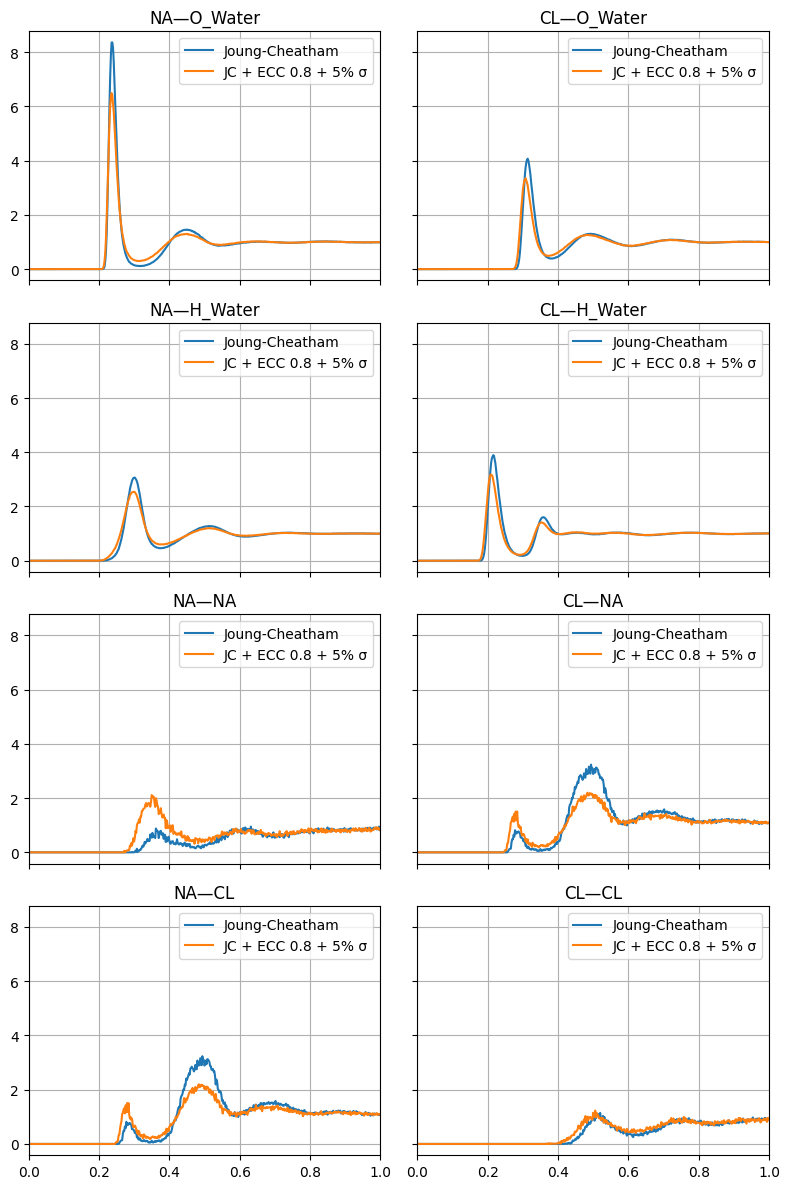

In [15]:
paths = [
    
    PROJECT_DIR / 'forcefields' / 'NaCl_js_test',
]

refs = ['NA', 'CL']
sels = ['O_Water', 'H_Water', 'NA', 'CL']

fig, axarr = plt.subplots(ncols=len(refs), nrows=len(sels), sharex=True, sharey=True, figsize=(4*len(refs), 3*len(sels)))
for j, ref in enumerate(refs):
    for i, sel in enumerate(sels):
        rdf_jc = np.loadtxt(PROJECT_DIR / 'forcefields' / 'NaCl_jc_test' / f'rdf_{ref}_{sel}.xvg', comments=['@', '#'])
        axarr[i, j].plot(rdf_jc[:, 0], rdf_jc[:, 1], label="Joung-Cheatham")
        rdf_js = np.loadtxt(PROJECT_DIR / 'forcefields' / 'NaCl_js_test' / f'rdf_{ref}_{sel}.xvg', comments=['@', '#'])
        axarr[i, j].plot(rdf_js[:, 0], rdf_js[:, 1], label="JC + ECC 0.8 + 5% σ")
        axarr[i, j].set_title(f"{ref}—{sel}")
        axarr[i, j].legend()
        axarr[i, j].grid()
        axarr[i, j].set_xlim(0, 1)
plt.tight_layout()
plt.savefig("figures/NaClECC.pdf")